## Bussiness problem Understanding
The main business problem is to identify the factors associated with insurance claim approval by analyzing customer and policy information.
The dataset contains information such as age, annual income, policy type, policy tenure, premium amount, claim amount, previous claims count, employment status, documentation status, payment history, claim reason, and fraud indicators. These factors can be analyzed to understand their relationship with insurance claim approval.

## Data Collection

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns
import warnings
warnings.simplefilter('ignore')

In [2]:
df=pd.read_excel(r"C:\Users\yarlagadda sindhu\Downloads\insurance_claim_approval_dataset.xlsx")
df

,Claim_ID,Age,Annual_Income,Policy_Type,Policy_Tenure_Years,Premium_Amount,Claim_Amount,Previous_Claims_Count,Employment_Status,Documentation_Complete,Payment_History,Claim_Reason,Fraud_Flag,Claim_Approved
0,CLM00001,67,1216528,Motor,2,19795,27153,1,Self-employed,No,Good,Accident,No,1
1,CLM00002,28,884933,Home,6,10576,77099,1,Unemployed,Yes,Poor,Natural_Damage,No,0
2,CLM00003,19,691346,Motor,12,21174,42273,0,Salaried,Yes,Average,Accident,No,1
3,CLM00004,55,663785,Home,8,25122,145045,1,Retired,Yes,Good,Other,No,1
4,CLM00005,39,758233,Health,7,22445,182404,1,Salaried,Yes,Good,Medical,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,CLM00596,25,480479,Health,5,27316,49736,1,Salaried,Yes,Good,Other,No,1
596,CLM00597,31,595337,Life,15,17363,68756,1,Self-employed,Yes,Good,Natural_Damage,No,1
597,CLM00598,47,1023771,Home,14,17159,47028,0,Salaried,Yes,Good,Natural_Damage,No,1
598,CLM00599,51,953935,Motor,6,17556,32359,0,Self-employed,Yes,Average,Other,No,1


## Data Understanding

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Claim_ID                600 non-null    object
 1   Age                     600 non-null    int64 
 2   Annual_Income           600 non-null    int64 
 3   Policy_Type             600 non-null    object
 4   Policy_Tenure_Years     600 non-null    int64 
 5   Premium_Amount          600 non-null    int64 
 6   Claim_Amount            600 non-null    int64 
 7   Previous_Claims_Count   600 non-null    int64 
 8   Employment_Status       600 non-null    object
 9   Documentation_Complete  600 non-null    object
 10  Payment_History         600 non-null    object
 11  Claim_Reason            600 non-null    object
 12  Fraud_Flag              600 non-null    object
 13  Claim_Approved          600 non-null    int64 
dtypes: int64(7), object(7)
memory usage: 65.8+ KB


In [4]:
df.shape

(600, 14)

In [5]:
df.columns

Index(['Claim_ID', 'Age', 'Annual_Income', 'Policy_Type',
       'Policy_Tenure_Years', 'Premium_Amount', 'Claim_Amount',
       'Previous_Claims_Count', 'Employment_Status', 'Documentation_Complete',
       'Payment_History', 'Claim_Reason', 'Fraud_Flag', 'Claim_Approved'],
      dtype='object')

In [6]:
df.size

8400

In [7]:
df.describe()

,Age,Annual_Income,Policy_Tenure_Years,Premium_Amount,Claim_Amount,Previous_Claims_Count,Claim_Approved
count,600.000000,6.000000e+02,600.000000,600.000000,600.000000,600.000000,600.000000
mean,45.930000,6.570209e+05,8.186667,21589.503333,100297.656667,0.736667,0.805000
std,16.595002,2.391428e+05,4.338571,8466.107367,68231.673507,0.851585,0.396531
min,18.000000,1.500000e+05,1.000000,4000.000000,13239.000000,0.000000,0.000000
25%,32.000000,4.875320e+05,4.000000,15475.250000,52893.000000,0.000000,1.000000
50%,45.000000,6.597055e+05,9.000000,21539.000000,81505.000000,1.000000,1.000000
75%,60.000000,8.199455e+05,12.000000,27245.750000,129565.000000,1.000000,1.000000
max,75.000000,1.426696e+06,15.000000,50335.000000,531473.000000,4.000000,1.000000


In [8]:
df['Policy_Type'].value_counts()

Policy_Type
Motor     223
Health    203
Home      107
Life       67
Name: count, dtype: int64

In [9]:
df['Employment_Status'].value_counts()

Employment_Status
Salaried         287
Self-employed    186
Unemployed        84
Retired           43
Name: count, dtype: int64

In [10]:
df['Documentation_Complete'].value_counts()

Documentation_Complete
Yes    487
No     113
Name: count, dtype: int64

In [11]:
df['Payment_History'].value_counts()

Payment_History
Good       399
Average    159
Poor        42
Name: count, dtype: int64

In [12]:
df['Claim_Reason'].value_counts()

Claim_Reason
Other             132
Theft             125
Accident          122
Medical           115
Natural_Damage    106
Name: count, dtype: int64

In [13]:
df['Fraud_Flag'].value_counts()

Fraud_Flag
No     568
Yes     32
Name: count, dtype: int64

In [14]:
df["Claim_Approved"].value_counts()

Claim_Approved
1    483
0    117
Name: count, dtype: int64

In [15]:
# Continuous=['Annual_Income','Premium_Amount','Claim_Amount']
# Discrete=['Age','Policy_Tenure_Years','Previous_Claims_Count']
# Categorical=['Policy_Type','Employment_Status','Documentation_Complete','Payment_History','Claim_Reason','Fraud_Flag','Claim_Approved']

## Data Preprocessing

### EDA

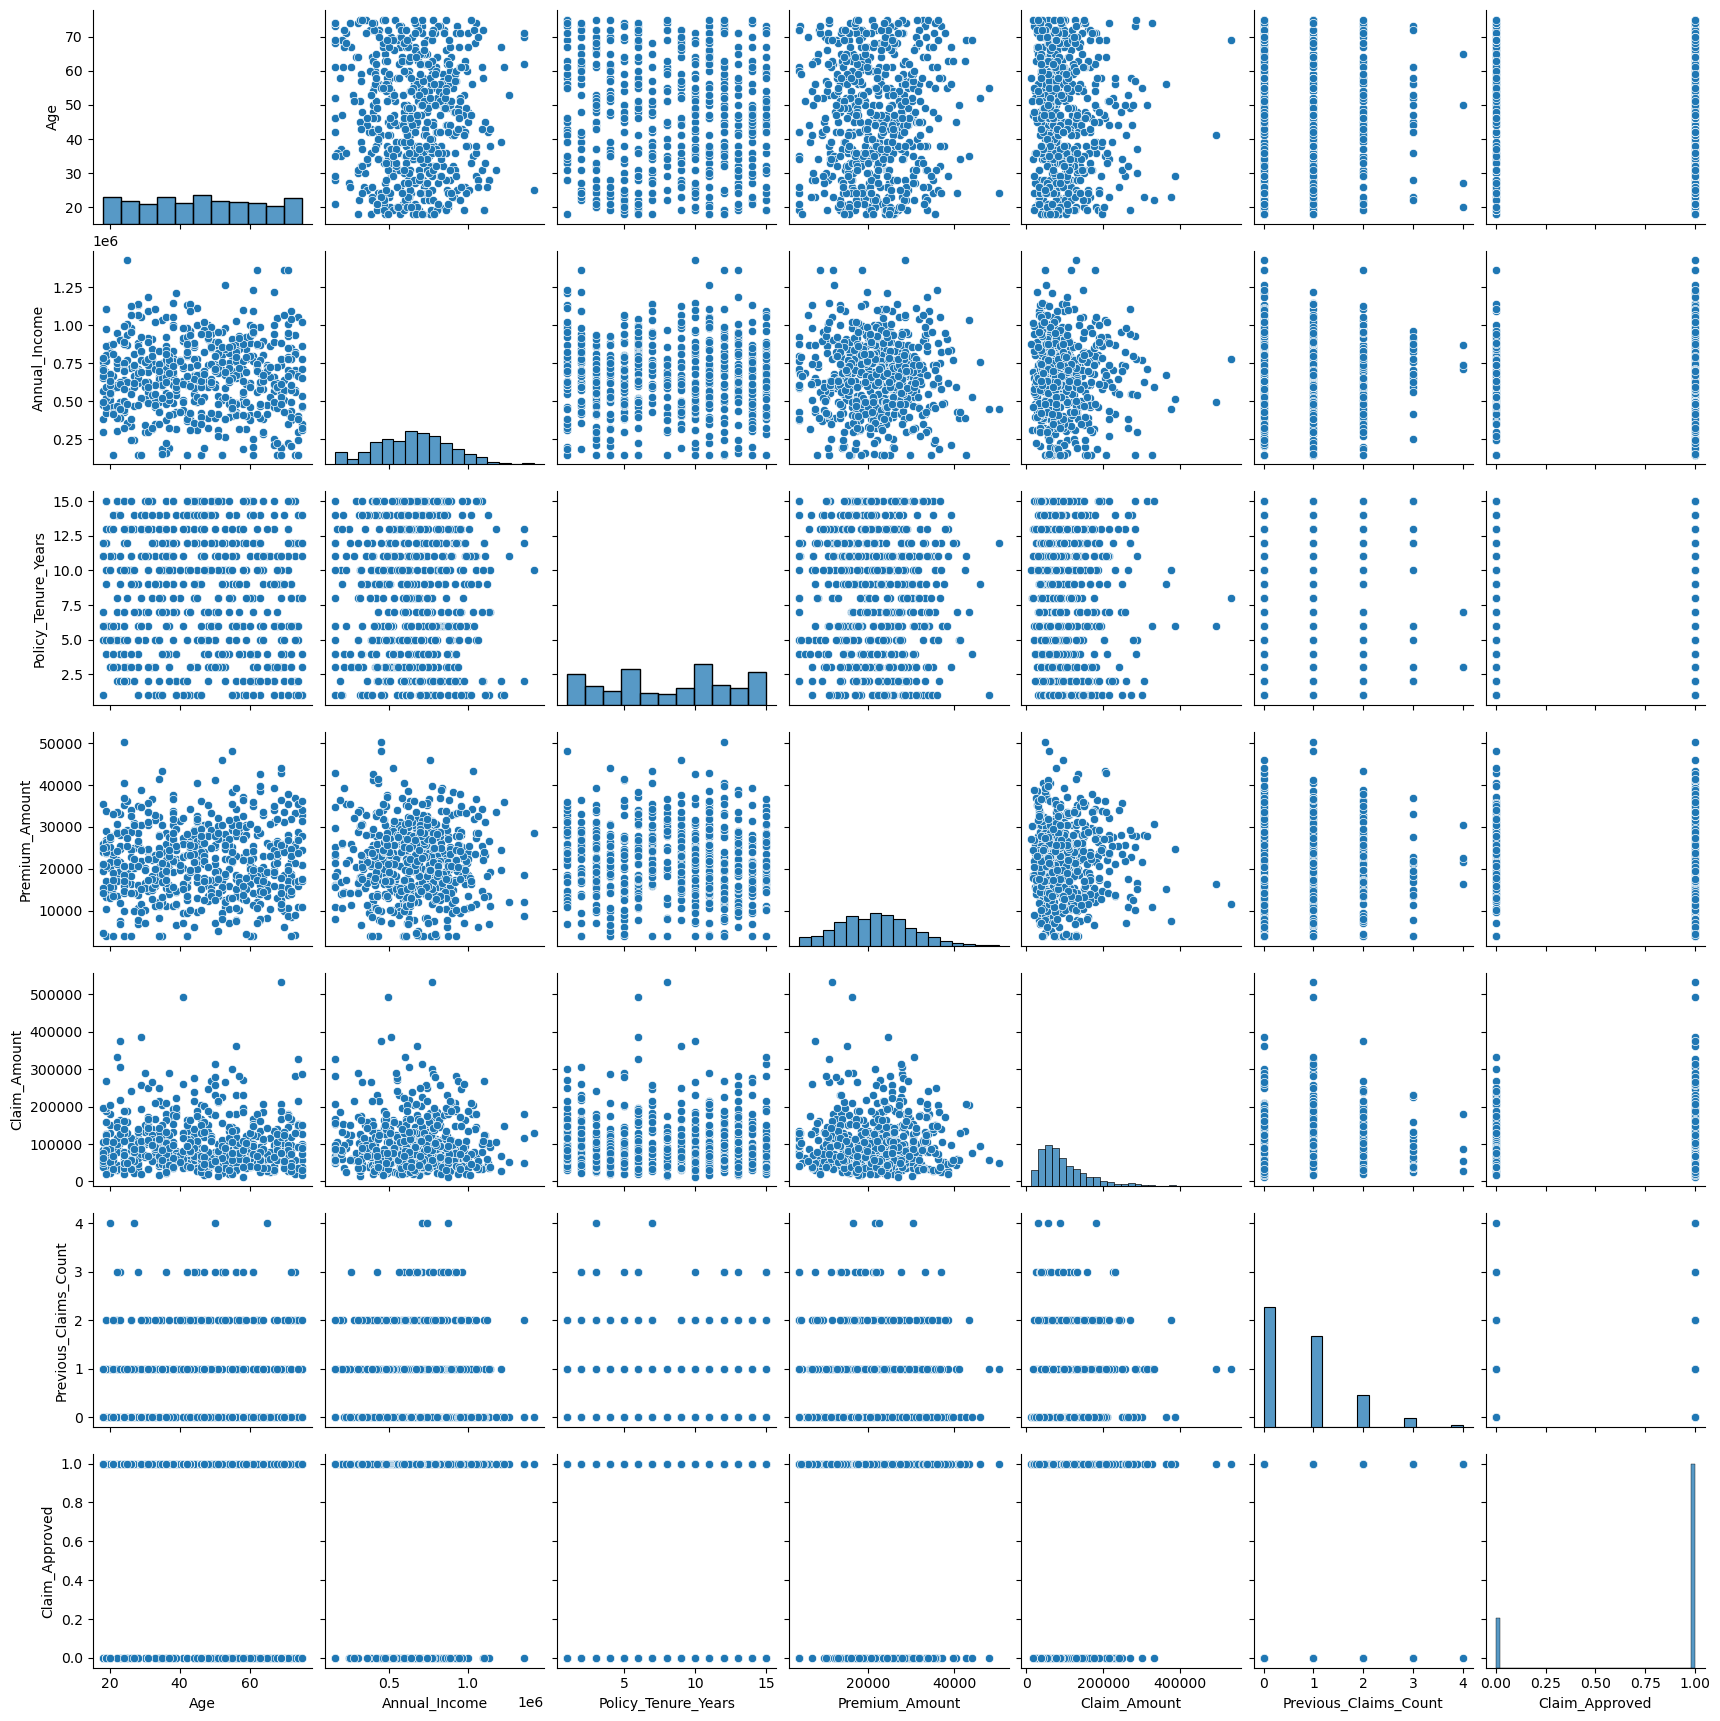

In [16]:
sns.pairplot(df)
plt.show()

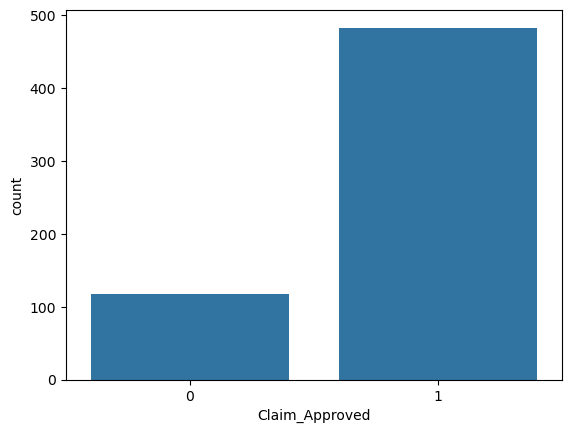

In [17]:
sns.countplot(x='Claim_Approved',data=df)
plt.show()

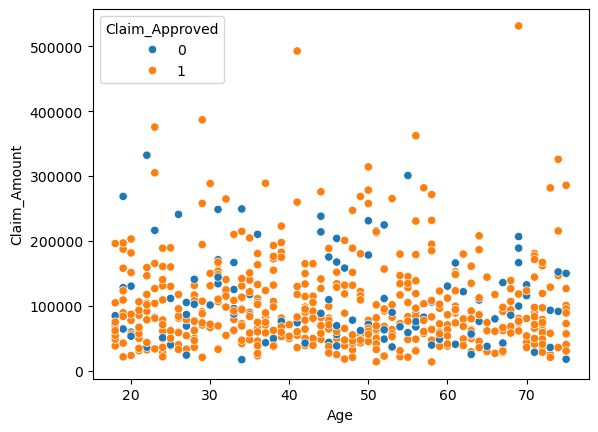

In [18]:
sns.scatterplot(data=df, x='Age', y='Claim_Amount',hue='Claim_Approved')
plt.show()

### Data Cleaning

In [19]:
df.isnull().sum()

Claim_ID                  0
Age                       0
Annual_Income             0
Policy_Type               0
Policy_Tenure_Years       0
Premium_Amount            0
Claim_Amount              0
Previous_Claims_Count     0
Employment_Status         0
Documentation_Complete    0
Payment_History           0
Claim_Reason              0
Fraud_Flag                0
Claim_Approved            0
dtype: int64

“There are no null values in the dataset.So, there is no need to handle.”

### Encoding

In [20]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df["Policy_Type"]=le.fit_transform(df["Policy_Type"])
df["Employment_Status"]=le.fit_transform(df["Employment_Status"])
df["Documentation_Complete"]=le.fit_transform(df["Documentation_Complete"])
df["Payment_History"]=le.fit_transform(df["Payment_History"])
df["Claim_Reason"]=le.fit_transform(df["Claim_Reason"])                                        
df["Fraud_Flag"]=le.fit_transform(df["Fraud_Flag"])
df["Claim_Approved"]=le.fit_transform(df["Claim_Approved"])                                    
df

,Claim_ID,Age,Annual_Income,Policy_Type,Policy_Tenure_Years,Premium_Amount,Claim_Amount,Previous_Claims_Count,Employment_Status,Documentation_Complete,Payment_History,Claim_Reason,Fraud_Flag,Claim_Approved
0,CLM00001,67,1216528,3,2,19795,27153,1,2,0,1,0,0,1
1,CLM00002,28,884933,1,6,10576,77099,1,3,1,2,2,0,0
2,CLM00003,19,691346,3,12,21174,42273,0,1,1,0,0,0,1
3,CLM00004,55,663785,1,8,25122,145045,1,0,1,1,3,0,1
4,CLM00005,39,758233,0,7,22445,182404,1,1,1,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,CLM00596,25,480479,0,5,27316,49736,1,1,1,1,3,0,1
596,CLM00597,31,595337,2,15,17363,68756,1,2,1,1,2,0,1
597,CLM00598,47,1023771,1,14,17159,47028,0,1,1,1,2,0,1
598,CLM00599,51,953935,3,6,17556,32359,0,2,1,0,3,0,1


### Feature Scaling

In [21]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
df['Age_sc']=sc.fit_transform(df[["Age"]])
df['Annual_Income_sc']=sc.fit_transform(df[["Annual_Income"]])
df['Premium_Amount_sc']=sc.fit_transform(df[["Premium_Amount"]])
df['Claim_Amount_sc']=sc.fit_transform(df[["Claim_Amount"]])
df

,Claim_ID,Age,Annual_Income,Policy_Type,Policy_Tenure_Years,Premium_Amount,Claim_Amount,Previous_Claims_Count,Employment_Status,Documentation_Complete,Payment_History,Claim_Reason,Fraud_Flag,Claim_Approved,Age_sc,Annual_Income_sc,Premium_Amount_sc,Claim_Amount_sc
0,CLM00001,67,1216528,3,2,19795,27153,1,2,0,1,0,0,1,1.270719,2.341588,-0.212140,-1.072899
1,CLM00002,28,884933,1,6,10576,77099,1,3,1,2,2,0,0,-1.081347,0.953833,-1.301979,-0.340282
2,CLM00003,19,691346,3,12,21174,42273,0,1,1,0,0,0,1,-1.624132,0.143654,-0.049119,-0.851116
3,CLM00004,55,663785,1,8,25122,145045,1,0,1,1,3,0,1,0.547006,0.028308,0.417600,0.656362
4,CLM00005,39,758233,0,7,22445,182404,1,1,1,1,1,0,1,-0.417944,0.423582,0.101134,1.204351
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,CLM00596,25,480479,0,5,27316,49736,1,1,1,1,3,0,1,-1.262275,-0.738844,0.676967,-0.741647
596,CLM00597,31,595337,2,15,17363,68756,1,2,1,1,2,0,1,-0.900419,-0.258153,-0.499643,-0.462659
597,CLM00598,47,1023771,1,14,17159,47028,0,1,1,1,2,0,1,0.064531,1.534883,-0.523759,-0.781369
598,CLM00599,51,953935,3,6,17556,32359,0,2,1,0,3,0,1,0.305769,1.242613,-0.476827,-0.996536


In [22]:
df = df.drop(['Age', 'Annual_Income', 'Premium_Amount' , 'Claim_Amount'], axis=1)

## X & Y

In [23]:
X= df.drop(['Claim_ID', 'Claim_Approved'], axis=1)
y= df['Claim_Approved']

### Data Balancing

##### Oversampling of Minority Class by duplication

In [27]:
from imblearn.over_sampling import RandomOverSampler
ROS=RandomOverSampler(random_state=42)
X,y=ROS.fit_resample(X,y)

print('After undersampling dataset shape')
print('---------------------------------')

y.value_counts()

After undersampling dataset shape
---------------------------------


Claim_Approved
1    483
0    483
Name: count, dtype: int64

## Train Test Split

In [28]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

## Models

###  1.Logestic Regression

In [29]:
# modelling
from sklearn.linear_model import LogisticRegression  
log_model=LogisticRegression()                         
log_model.fit(X_train,y_train)                                
          


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [30]:
# Predictions
ypred_train=log_model.predict(X_train)           
ypred_test=log_model.predict(X_test)  

In [31]:
# Train Test Split
from sklearn.metrics import accuracy_score
print(accuracy_score(y_train,ypred_train))  
print(accuracy_score(y_test,ypred_test))  

0.665680473372781
0.6


In [32]:
from sklearn.model_selection import cross_val_score
scores=cross_val_score(log_model,X,y,cv=5)
print("Cross Validation Score:",scores.mean())

cv_score=scores.mean()


Cross Validation Score: 0.6273436248063672


In [33]:
from sklearn.model_selection import GridSearchCV
estimator = LogisticRegression()
param_grid = {"C": [0.01, 0.1, 1, 10, 100]}

model_hp = GridSearchCV(estimator,param_grid,cv=5,scoring='accuracy')

model_hp.fit(X_train, y_train)

model_hp.best_params_

{'C': 0.1}

In [38]:
# modelling
from sklearn.linear_model import LogisticRegression  
log_model=LogisticRegression(C=0.1)                         
log_model.fit(X_train,y_train)

# Predictions
ypred_train=log_model.predict(X_train)           
ypred_test=log_model.predict(X_test)  

# Train Test Split
from sklearn.metrics import accuracy_score
print(accuracy_score(y_train,ypred_train))  
print(accuracy_score(y_test,ypred_test)) 

from sklearn.model_selection import cross_val_score
scores=cross_val_score(knn_model,X,y,cv=5)
scores.mean()



0.6523668639053254
0.5896551724137931


np.float64(0.6894770578494738)

## 2.KNN Algorithm

In [39]:
# Default Modeling
from sklearn.neighbors import KNeighborsClassifier
knn_model=KNeighborsClassifier()
knn_model.fit(X_train,y_train)

# prediction
y_pred_train=knn_model.predict(X_train)
y_pred_test=knn_model.predict(X_test)

# Evaluation

# 1.Train & Test Accuracy
from sklearn.metrics import accuracy_score
print(accuracy_score(y_train,y_pred_train))   
print(accuracy_score(y_test,y_pred_test))

# 2.Cross Validation
from sklearn.model_selection import cross_val_score
scores=cross_val_score(knn_model,X,y,cv=5)
scores.mean()

0.7988165680473372
0.6827586206896552


np.float64(0.6894770578494738)

In [40]:
from sklearn.model_selection import GridSearchCV
estimator=KNeighborsClassifier()
param_grid={'n_neighbors':list(range(1,31)),'p':[1,2]}

cv_classifier=GridSearchCV(estimator,param_grid,cv=5,scoring='accuracy')
cv_classifier.fit(X_train,y_train)
cv_classifier.best_params_

{'n_neighbors': 1, 'p': 2}

In [41]:
from sklearn.neighbors import KNeighborsClassifier
knn_model=KNeighborsClassifier(n_neighbors=1,p=2)
knn_model.fit(X_train,y_train)

# prediction
y_pred_train=knn_model.predict(X_train)
y_pred_test=knn_model.predict(X_test)

# Evaluation

# 1.Train & Test Accuracy
from sklearn.metrics import accuracy_score
print(accuracy_score(y_train,y_pred_train))   
print(accuracy_score(y_test,y_pred_test))

# 2.Cross Validation
from sklearn.model_selection import cross_val_score
scores=cross_val_score(knn_model,X,y,cv=5)
scores.mean()

1.0
0.8724137931034482


np.float64(0.8737567437636878)

## 3.Decision Tree

In [42]:
# Decision Tree Classifer-With default parameteres
from sklearn.tree import DecisionTreeClassifier
dt_default=DecisionTreeClassifier(random_state=0)
dt_default.fit(X_train,y_train)

# prediction
pred_train=dt_default.predict(X_train)            
base_pred=dt_default.predict(X_test)  

# EValuation

# 1.Train and test accuracy
from sklearn.metrics import accuracy_score
print("Train accuracy:",accuracy_score(pred_train,y_train))  
print("Tesst accuracy:",accuracy_score(base_pred,y_test)) 

# 2.Cross validation
from sklearn.model_selection import cross_val_score
scores=cross_val_score(dt_default,X,y,cv=5)
print("Cross Validation Score:",scores.mean())

cv_score=scores.mean()


Train accuracy: 1.0
Tesst accuracy: 0.8517241379310345
Cross Validation Score: 0.8861439025693072


In [43]:
from sklearn.model_selection import GridSearchCV
# model
estimator=DecisionTreeClassifier(random_state=0)
# parameters
param_grid={"criterion":["gini","entropy"],"max_depth":[1,2,3,4,]}

grid=GridSearchCV(estimator,param_grid,scoring="accuracy",cv=5)

grid.fit(X_train,y_train)

grid.best_params_

{'criterion': 'gini', 'max_depth': 4}

In [44]:
dt_bhp=DecisionTreeClassifier(criterion='gini',max_depth=4,random_state=0)
dt_bhp.fit(X_train, y_train)

ypred_train=dt_bhp.predict(X_train)
ypred_test=dt_bhp.predict(X_test)

print("Train accuracy:",accuracy_score(ypred_train,y_train))  
print("Tesst accuracy:",accuracy_score(ypred_test,y_test)) 

scores=cross_val_score(dt_bhp,X,y,cv=5)

print("Cross Validation Score:",scores.mean())

Train accuracy: 0.7130177514792899
Tesst accuracy: 0.6620689655172414
Cross Validation Score: 0.6552908498477645


## 4.SVM

In [45]:
#modelling
from sklearn.ensemble import AdaBoostClassifier
model=AdaBoostClassifier()
model.fit(X_train,y_train)

#Prediction
ypred_train=model.predict(X_train)
predictions=model.predict(X_test)

#Evaluation

#1.Train & Test Accuracy
from sklearn.metrics import accuracy_score
print("Train accuracy:",accuracy_score(y_train,ypred_train))
print("Test accuracy:",accuracy_score(y_test,predictions))

#2.Crossvalidation
from sklearn.model_selection import cross_val_score
scores=cross_val_score(model,X,y,cv=5)
print("Cross Validation Score:",scores.mean())

Train accuracy: 0.742603550295858
Test accuracy: 0.696551724137931
Cross Validation Score: 0.6853480049142673


In [46]:
from sklearn.model_selection import GridSearchCV
estimator=AdaBoostClassifier()
param_grid={'n_estimators':list(range(1,51))}
grid=GridSearchCV(estimator,param_grid,cv=5,scoring='accuracy')
grid.fit(X_train,y_train)
grid.best_params_

{'n_estimators': 44}

In [47]:

# Modelling
from sklearn.ensemble import AdaBoostClassifier

ada_bhp = AdaBoostClassifier(n_estimators=44)
ada_bhp.fit(X_train, y_train)

# Prediction
ypred_train = ada_bhp.predict(X_train)
predictions = ada_bhp.predict(X_test)

# Evaluation
from sklearn.metrics import accuracy_score

print("Train accuracy:", accuracy_score(y_train, ypred_train))
print("Test accuracy:", accuracy_score(y_test, predictions))

# Cross-validation
from sklearn.model_selection import cross_val_score

scores = cross_val_score(ada_bhp, X_train, y_train, cv=5)
print("Cross Validation Score:", scores.mean())


Train accuracy: 0.742603550295858
Test accuracy: 0.696551724137931
Cross Validation Score: 0.6996187363834423


## 5.XG Boost

In [48]:
# modeling
from xgboost import XGBClassifier
xgb_model=XGBClassifier()
xgb_model.fit(X_train,y_train)

# prediction
y_pred_train=xgb_model.predict(X_train)
y_pred_test=xgb_model.predict(X_test)

#Evaluation

#1.Train & Test Accuracy
from sklearn.metrics import accuracy_score
print(accuracy_score(y_train,y_pred_train))
print(accuracy_score(y_test,y_pred_test))

#2.Crossvalidation
from sklearn.model_selection import cross_val_score
scores=cross_val_score(estimator=xgb_model,X=X,y=y,cv=5)
print("Cross Validation Score:",scores.mean())

1.0
0.9
Cross Validation Score: 0.9140964692057049


In [49]:
from sklearn.model_selection import GridSearchCV
estimator=XGBClassifier()

param_grid={'n_estimators':[10,20,40,100],'max_depth':[3,4,5],'gamma':[0,0.15,0.3,0.5,1]}
grid=GridSearchCV(xgb_model,param_grid,cv=5,scoring='accuracy')
grid.fit(X_train,y_train)
grid.best_params_

{'gamma': 0.15, 'max_depth': 5, 'n_estimators': 100}

In [50]:
feats=pd.DataFrame(data=grid.best_estimator_.feature_importances_,index=X.columns,columns=['Importance'])
important_features=feats[feats['Importance']>0.01]
imp_features_list=feats[feats['Importance']>0.01].index.to_list()
imp_features_list

['Policy_Type',
 'Policy_Tenure_Years',
 'Previous_Claims_Count',
 'Employment_Status',
 'Documentation_Complete',
 'Payment_History',
 'Claim_Reason',
 'Fraud_Flag',
 'Age_sc',
 'Annual_Income_sc',
 'Premium_Amount_sc',
 'Claim_Amount_sc']

In [51]:
X_imp=X[imp_features_list]          

X_train,X_test,y_train,y_test=train_test_split(X_imp,y,test_size=0.2,random_state=101)

#modelling
xgb_bhp=XGBClassifier(gamma=0.15,max_depth=5,n_estimators=100)
xgb_bhp.fit(X_train,y_train)

#Prediction
ypred_train=xgb_bhp.predict(X_train)
predictions=xgb_bhp.predict(X_test)

#Evaluation

#1.Train & Test Accuracy
from sklearn.metrics import accuracy_score
print("Train accuracy:",accuracy_score(y_train,ypred_train))
print("Test accuracy:",accuracy_score(y_test,predictions))

#2.Crossvalidation
from sklearn.model_selection import cross_val_score
scores=cross_val_score(xgb_bhp,X,y,cv=5)
print("Cross Validation Score:",scores.mean())

Train accuracy: 1.0
Test accuracy: 0.9381443298969072
Cross Validation Score: 0.9078788526253939


## Model  Performance Comaparission table

In [54]:
accuracy_table = pd.DataFrame({'Algorithm Name': ['Logistic Regression','KNN','Decision Tree','AdaBoost','XGBoost'],
'Test Accuracy': [0.6000,0.8724,0.6621,0.6966,0.9381],
'Train Accuracy': [0.6657,1.0000,0.7130,0.7426,1.0000],
'CV Score': [0.6273,0.8738,0.6553,0.6996,0.9079]})

accuracy_table


,Algorithm Name,Test Accuracy,Train Accuracy,CV Score
0,Logistic Regression,0.6000,0.6657,0.6273
1,KNN,0.8724,1.0000,0.8738
2,Decision Tree,0.6621,0.7130,0.6553
3,AdaBoost,0.6966,0.7426,0.6996
4,XGBoost,0.9381,1.0000,0.9079


## Conclusion

In this project, XGBoost is selected as the best-performing model because it achieved the highest test accuracy of 93.81% among the compared algorithms. It also obtained a cross-validation score of 90.79%, indicating good performance across the validation folds. Although KNN achieved a test accuracy of 87.24%, XGBoost performed better on the test data. Therefore, XGBoost is selected as the best model based on test accuracy and cross-validation performance.

## Save the model

In [55]:
from joblib import dump

In [56]:
dump(model,'xgb_model.joblib')

['xgb_model.joblib']

## Load the model

In [57]:
from joblib import load

In [58]:
loaded_model=load('xgb_model.joblib')